# Q09 - P-creativity to H-creativity with an Evolutionary Algorithm

Same code as `q09_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q9 - P-creativity through an evolutionary algorithm, and the step up to H-creativity.

Designs are small vehicles (6 genes). P-creative = new to THIS agent (far from its own archive).
H-creative = new to HISTORY (far from 300 known designs) AND useful. Three runs compare the
plain P-creative EA with two fixes: a global archive and a conceptual-space expansion (new gene).
"""
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

GENES = ["length", "height", "wheel_size", "wheel_gap", "roof_slope", "colour"]
PROTOTYPES = np.array([  # sedan, SUV, truck, bus, sports car (all follow the "useful" rules)
    [0.55, 0.40, 0.24, 0.41, 0.45, 0.2], [0.60, 0.65, 0.33, 0.45, 0.30, 0.5],
    [0.85, 0.75, 0.36, 0.64, 0.20, 0.7], [0.95, 0.85, 0.40, 0.71, 0.10, 0.9],
    [0.50, 0.25, 0.19, 0.38, 0.55, 0.1]])
HISTORY = np.clip(np.repeat(PROTOTYPES, 60, axis=0)
                  + np.random.default_rng(1).normal(0, 0.05, (300, 6)), 0, 1)
TAU_P, TAU_H, MIN_USE, SWITCH = 0.12, 0.40, 0.70, 20


def usefulness(x: np.ndarray) -> np.ndarray:
    """Engineering rules: wheels near the ends, wheels sized to the body, roof not too steep."""
    err = (np.abs(x[:, 3] - 0.75 * x[:, 0]) + np.abs(x[:, 2] - (0.35 * x[:, 1] + 0.1))
           + np.maximum(0, x[:, 4] - 0.6))
    base = np.clip(1 - 2 * err, 0, 1)
    return base if x.shape[1] == 6 else 0.8 * base + 0.2 * x[:, 6]  # gene 7: smart IoT skin


def knn_distance(x: np.ndarray, archive: np.ndarray, k: int = 3) -> np.ndarray:
    if len(archive) == 0:
        return np.ones(len(x))
    d = np.sqrt(((x[:, None, :] - archive[None, :, :]) ** 2).sum(-1))
    return np.sort(d, axis=1)[:, :k].mean(axis=1)


def pad(a: np.ndarray, dims: int) -> np.ndarray:
    return np.hstack([a, np.zeros((len(a), dims - a.shape[1]))]) if a.shape[1] < dims else a


def evolve(fix: str, gens: int = 40, size: int = 40, seed: int = 9) -> dict:
    """fix: 'P-only', 'global' (global archive), 'global+expand' (+ new gene after SWITCH)."""
    rng = np.random.default_rng(seed)
    pop, own = rng.random((size, 6)), np.empty((0, 6))
    log = {"p_new": [], "h_new": [], "points": []}
    for g in range(1, gens + 1):
        if fix == "global+expand" and g == SWITCH + 1:  # transform the conceptual space
            pop = np.hstack([pop, rng.random((size, 1)) * 0.3])
            own = pad(own, 7)
        history, use = pad(HISTORY, pop.shape[1]), usefulness(pop)
        nov_h = knn_distance(pop, history, k=1)
        p_count = h_count = 0
        for i, x in enumerate(pop):  # count P- and H-creative designs of this generation
            if knn_distance(x[None], own, k=1)[0] > TAU_P:
                own, p_count = np.vstack([own, x]), p_count + 1
                is_h = nov_h[i] > TAU_H and use[i] > MIN_USE
                h_count += is_h
                log["points"].append((g, nov_h[i], use[i], x[0], x[1], is_h))
        log["p_new"].append(p_count)
        log["h_new"].append(h_count)
        fit = use + 0.5 * knn_distance(pop, own)  # P-creativity: novelty to own archive
        if fix != "P-only" and g > SWITCH:
            fit = use + 0.3 * knn_distance(pop, own) + 0.6 * nov_h  # global archive novelty
        elite = pop[np.argsort(-fit)[:2]]
        pairs = rng.integers(0, size, (size - 2, 2, 3))  # tournaments of 3
        parents = np.take_along_axis(pairs, fit[pairs].argmax(-1)[..., None], -1)[..., 0]
        alpha = rng.random((size - 2, 1))
        kids = alpha * pop[parents[:, 0]] + (1 - alpha) * pop[parents[:, 1]]  # blend crossover
        kids += rng.normal(0, 0.08, kids.shape) * (rng.random(kids.shape) < 0.3)  # mutation
        pop = np.clip(np.vstack([elite, kids]), 0, 1)
    return log


runs = {name: evolve(name) for name in ["P-only", "global", "global+expand"]}
main = runs["global+expand"]
print("Q9  P-creativity -> H-creativity with an evolutionary algorithm (vehicle designs)")
print(f"History archive: {len(HISTORY)} known designs | P-new: dist to own archive > {TAU_P} | "
      f"H-new: dist to history > {TAU_H} and usefulness > {MIN_USE}")
print("Run 'global+expand': generations 1-20 plain EA, from 21 global archive + new gene")
print(f"{'gens':>7} | {'P-creative':>10} | {'H-creative':>10} | share H")
for a in range(0, 40, 5):
    p, h = sum(main["p_new"][a:a + 5]), sum(main["h_new"][a:a + 5])
    print(f"{a + 1:>3}-{a + 5:<3} | {p:>10} | {h:>10} | {h / max(p, 1):6.1%}")
print("Totals after 40 generations:")
for name, log in runs.items():
    p, h = sum(log["p_new"]), sum(log["h_new"])
    print(f"  {name:<14} P-creative {p:>4} | H-creative {h:>3} | H share {h / max(p, 1):5.1%}")

# ---------------- charts ----------------
g = np.arange(1, 41)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
a1.bar(g, main["p_new"], color="#a8c5e2", label="P-creative (new to the agent)")
a1.bar(g, main["h_new"], color="#e76f51", label="H-creative (new to history + useful)")
a1.axvline(SWITCH + 0.5, color="#2a9d8f", ls="--")
a1.text(SWITCH + 1, max(main["p_new"]) * 0.9, "global archive +\nnew gene added", color="#2a9d8f", fontsize=8.5)
a1.set_xlabel("generation")
a1.set_ylabel("designs")
a1.set_title("New designs per generation (run with both fixes)")
a1.legend(fontsize=8)
for (name, log), colour in zip(runs.items(), ["#9ca3af", "#3a6ea5", "#e76f51"]):
    a2.plot(g, np.cumsum(log["h_new"]), color=colour, lw=2, label=name)
a2.axvline(SWITCH + 0.5, color="#2a9d8f", ls="--")
a2.set_xlabel("generation")
a2.set_ylabel("H-creative designs (cumulative)")
a2.set_title("Effect of each fix on H-creativity")
a2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q09_chart1_p_vs_h.png")
plt.close(fig)

pts = np.array([p[:5] for p in main["points"]])
is_h = np.array([p[5] for p in main["points"]], bool)
early = pts[:, 0] <= SWITCH
fig, (b1, b2) = plt.subplots(1, 2, figsize=(11, 4.1))
b1.axvspan(TAU_H, pts[:, 1].max() + 0.05, ymin=0, ymax=1, color="#2a9d8f", alpha=0.07)
b1.axhline(MIN_USE, color="#2a9d8f", ls=":")
b1.axvline(TAU_H, color="#2a9d8f", ls=":")
b1.scatter(pts[early, 1], pts[early, 2], s=14, color="#9ca3af", label="gens 1-20 (6 genes)")
b1.scatter(pts[~early, 1], pts[~early, 2], s=14, color="#3a6ea5", label="gens 21-40 (7 genes)")
b1.scatter(pts[is_h, 1], pts[is_h, 2], s=40, facecolors="none", edgecolors="#e76f51", label="H-creative")
b1.text(pts[:, 1].max(), 0.32, "H-creative zone:\nnew to history + useful", fontsize=8.5,
        color="#2a9d8f", ha="right")
b1.set_xlabel("distance to nearest historical design (H-novelty)")
b1.set_ylabel("usefulness")
b1.set_title("Creativity map: novelty vs value")
b1.legend(fontsize=8, loc="lower right")
b2.scatter(HISTORY[:, 0], HISTORY[:, 1], s=8, color="#d1d5db", label="history (300 known designs)")
b2.scatter(pts[~is_h, 3], pts[~is_h, 4], s=10, color="#a8c5e2", label="P-creative only")
b2.scatter(pts[is_h, 3], pts[is_h, 4], s=30, marker="*", color="#e76f51", label="H-creative")
b2.set_xlabel("body length")
b2.set_ylabel("body height")
b2.set_title("Where the new designs sit vs history")
b2.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("images/q09_chart2_creativity_map.png")
plt.close(fig)
print("charts saved to images/")


Q9  P-creativity -> H-creativity with an evolutionary algorithm (vehicle designs)
History archive: 300 known designs | P-new: dist to own archive > 0.12 | H-new: dist to history > 0.4 and usefulness > 0.7
Run 'global+expand': generations 1-20 plain EA, from 21 global archive + new gene
   gens | P-creative | H-creative | share H
  1-5   |        130 |         11 |   8.5%
  6-10  |         46 |          3 |   6.5%
 11-15  |         21 |          0 |   0.0%
 16-20  |         15 |          1 |   6.7%
 21-25  |         60 |         12 |  20.0%
 26-30  |         60 |         26 |  43.3%
 31-35  |         47 |         37 |  78.7%
 36-40  |         42 |         30 |  71.4%
Totals after 40 generations:
  P-only         P-creative  276 | H-creative  18 | H share  6.5%
  global         P-creative  294 | H-creative  33 | H share 11.2%
  global+expand  P-creative  421 | H-creative 120 | H share 28.5%


charts saved to images/


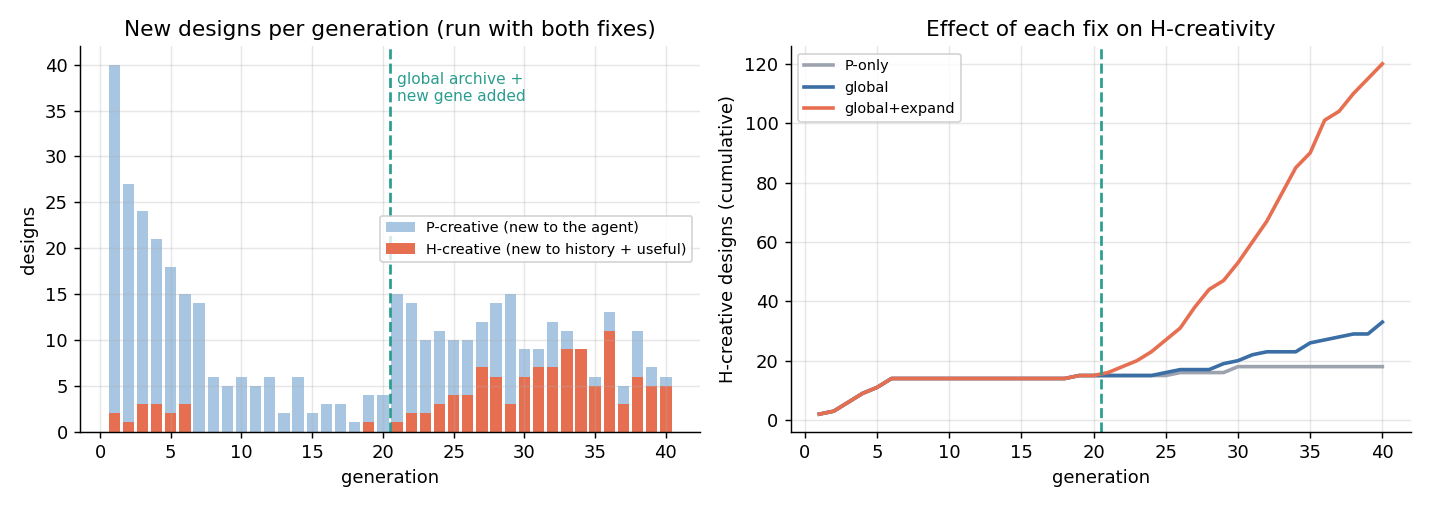

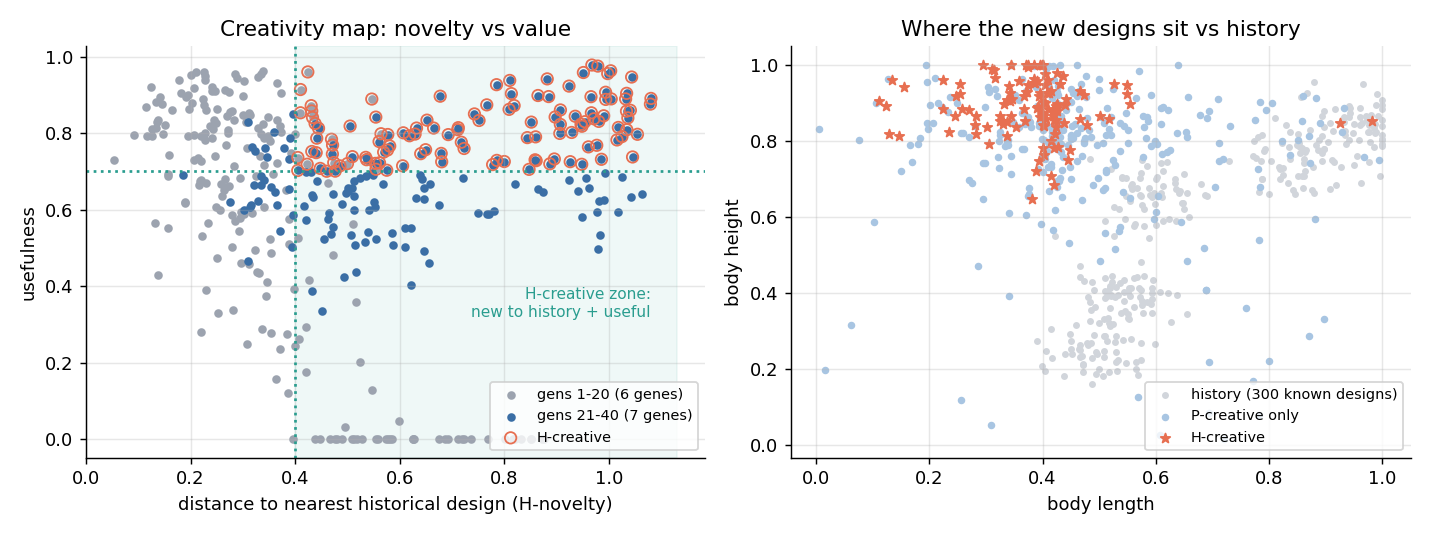

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q09_chart*.png')):
    display(Image(p))